**本节课介绍了关于线性回归模型的搭建和训练代码**
从 0 开始实现

# 准备训练样本

## 训练样本的生成

In [54]:
#导入包
%matplotlib inline
import random
import torch
from d2l import torch as d2l

In [55]:
#构造人造数据集（x, y 是线性数据，在加上一些噪声即可）
# y = X * w + b + e （ e 是噪声）
def synthetic_data(w, b, num_example): 
    # X 是均值为 0 方差为 1 的随机数（符合正态分布 N(0, 1)），其大小是：样本的个数 * 参数 w 的长度
    X = torch.normal(0, 1, (num_example, len(w)))
    #代入方程 y = X * w + b 计算 y ，注意 X * w 是矩阵乘法
    y = torch.matmul(X, w) + b
    #加上噪声
    y += torch.normal(0, 0.01, y.shape)
    #这里返回时要把 y.shape 从 (n, ) 变成 (n, 1) 
    #也就是从原来有 n 个元素的一维数组变成一个 n * 1 的二维数组（虽然元素一样，但含义不同）
    #而此处 -1 的含义是让 reshape 函数在元素个数不变的情况下自动计算该处的值（例如是 n ）
    return X, y.reshape(-1, 1)

In [56]:
#假设在 x y 的相关关系中的参数是 w = [2, -3.4], b = 4.2
true_w = torch.tensor([2, -3.4])
true_b = 4.2
#不妨生成 1000 个加上噪声的随机样本
features, labels = synthetic_data(true_w, true_b, 1000)

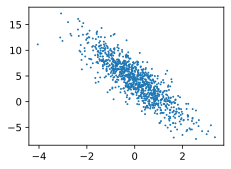

In [57]:
#不妨看一下训练样本的分布图
d2l.set_figsize()
#实际上由于每个 y 和两个自变量 x_1 x_2 有关（因为有 len(w) = 2）
#但此处为了方便展示，只取第一列的 w 个 x_1
d2l.plt.scatter(features[:, 1].detach().numpy(), labels.detach().numpy(), 1)

## 训练样本的读取

In [58]:
#定义一个函数，接受特征矩阵（样本 x）和标签（对应的 y）与批量大小，生成一个批量的数据
def data_iter(batch_size, features, labels):
    #由于 features 是一个二维矩阵 [[.][.]..] 所以 len() 返回行数
    num_example = len(features)
    #将 0 ~ （n - 1） 随机打乱，便于下一步获取由随机几行构成的随机样本
    indices = list(range(num_example))
    random.shuffle(indices)
    #步长设为 batch_size 代表每个批量获取这么多个样本
    for i in range(0, num_example, batch_size):
        batch_indices = torch.tensor(indices[i : min(i + batch_size, num_example)])
        #使用 yield 关键字，使得暂时返回这些样本并暂停函数运行
        #每次都可以返回一批新样本直到都返回完为止
        yield features[batch_indices], labels[batch_indices]

# 定义模型

## 初始化模型参数

In [80]:
#初始化训练前的 w 和 b ，这里的 requires_grad 参数代表告诉 torch 这是需要训练的参数而不是普通参数
#这可以让他在训练时自动求导（梯度下降算法求最优解的关键）
w = torch.normal(0, 0.1, size=(2, 1), requires_grad=True)
#这里将 b 设为一个元素是 0 的一维张量
b = torch.zeros(1, requires_grad=True)

## 定义线性模型

In [60]:
#这里的线性模型即我们定义的回归函数 y = X * w + b
def linreg(X, w, b):
    return torch.matmul(X, w) + b

## 定义损失函数

In [61]:
#用（真实值 - 训练值）^ 2 / 2 得到其中一个样本的误差
#这里为了到时候对其求导数时能把指数的 2 消去，故乘上 1 / 2 这个常数
def squared_loss(true_y, predic_y):
    return (true_y - predic_y.reshape(predic_y.shape)) ** 2 / 2

## 定义优化算法（参数迭代方式）

In [62]:
#这里 params 代表了所有需要更新迭代的所有参数（即 矩阵w 和 b ）
#lr 代表了学习率，每次要在梯度方向上更新多少的倍率（这也是一个超参数，有程序员决定
def SGD(params, lr, batch_size):
    #此处由于是更新参数的值，所以要先关闭梯度追踪
    #不然这个操作也会被追踪到并用于梯度的更新，然后不断循环卡死
    with torch.no_grad():
        for param in params:
            #公式：w = w - (learning_rate(学习率) / batch_size) * grad(导数)
            #由于 squared_loss() 函数算出来的是总梯度，所以这里要取平均
            param -= lr * param.grad / batch_size
            #由于 torch 不会自动重置导数，所有设置为 0
            param.grad.zero_()

# 定义训练过程

## 超参数设置

In [77]:
#以下是一些超参数，可以自己随便定义玩玩看
lr = 0.01 #学习率
num_epochs = 10 #训练次数
net = linreg #神经网络仅选用单层线性模型（没有多层）
loss = squared_loss #损失由我们定义的损失函数给出
batch_size = 10 #训练样本的批数

## 训练过程

In [87]:
for epoch in range(num_epochs):
    #每次拿出一个批量的训练样本
    for X, y in data_iter(batch_size, features, labels):
        #向损失函数中传入 真实值 和 （神经网络当前的）预测值，计算损失（误差）
        #此处 loss_ 的形状是 （batch_size, 1）
        loss_ = loss(y, net(X, w, b))
        #更新参数的梯度
        loss_.sum().backward()
        #更新迭代参数
        SGD([w, b], lr, batch_size)
    #结束该轮训练，打印出损失（其实也可以不用，这里是为了便于观察）
    with torch.no_grad():
        train_res = loss(net(features, w, b), labels)
        #这里由于 train_res 是一个大小为 （batch_size, 1） 的张量，所以用 mean() 取平均值输出
        print(f"epoch = {epoch + 1}, loss = {train_res.mean():.10f}")
print(F"The paramters after learning are: \n\
        w = [{w[0, 0]:.4f}, {w[1, 0]:.4f}]\n\
        b = {b[0]:.4f}\n")
print(f"The true (best) value if paramters are: \n\
        w = [{true_w[0]:.4f}, {true_w[1]:.4f}]\n\
        b = {true_b:.4f}\n")

epoch = 1, loss = 0.0000526725
epoch = 2, loss = 0.0000526708
epoch = 3, loss = 0.0000526761
epoch = 4, loss = 0.0000526814
epoch = 5, loss = 0.0000526760
epoch = 6, loss = 0.0000526675
epoch = 7, loss = 0.0000526682
epoch = 8, loss = 0.0000526705
epoch = 9, loss = 0.0000526817
epoch = 10, loss = 0.0000526730
The paramters after learning are: 
        w = [2.0002, -3.3997]
        b = 4.2005

The true (best) value if paramters are: 
        w = [2.0000, -3.4000]
        b = 4.2000

